In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

---
## 3. Initial Data Exploration

Before cleaning the data, we need to understand its structure and quality.

In this section, we will:
- Load the raw dataset.
- Check the number of rows and columns.
- Review column names and data types.
- Identify missing values and duplicate rows.
- Explore basic statistics for numerical columns.

These checks will help us decide how to prepare the data for analysis.


### 3.1 Dataset Overview

In [74]:
# Load the original data
df = pd.read_csv("../data/raw/Online Retail.csv")

# Display the first five rows
display(df.head())

# Check the size of the dataset
number_of_rows, number_of_columns = df.shape

print(f"Number of rows: {number_of_rows:,}")
print(f"Number of columns: {number_of_columns}")


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Number of rows: 541,909
Number of columns: 8



- The dataset contains 541,909 rows and 8 columns.
- Each row represents a product line within a transaction, so a single invoice may contain multiple rows.
- The first five rows show the main information available, including invoice numbers, product codes, quantities, prices, dates, customer IDs, and countries.
- This dataset provides the information needed to analyze sales performance, product demand, and customer purchasing behavior.


### 3.2 Column Names and Data Types

- The `info()` method shows the column names, data types, and number of non-missing values.
- This helps us identify columns that may need further preparation, such as dates stored as text or columns with missing values.


In [42]:
# Inspect column names, data types, and non-missing values
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB



- The dataset contains 8 columns with different data types.
- The `InvoiceDate` column is stored as text (`object`), so it needs to be converted to datetime format before analyzing sales trends over time.
- The `CustomerID` column is stored as a floating-point number because some customer IDs are missing. Since it is an identifier rather than a numerical measurement, we will handle it accordingly during customer analysis.
- The remaining columns provide information about invoices, products, quantities, prices, and countries.


### 3.3 Missing Values

In [45]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Display only columns that contain missing values
missing_values = missing_values[missing_values > 0]

display(missing_values.sort_values(ascending=False))


CustomerID     135080
Description      1454
dtype: int64


- The dataset contains 135,080 missing values in `CustomerID` and 1,454 missing values in `Description`.
- Missing customer IDs affect customer-level analysis because transactions cannot be reliably assigned to a specific customer. However, these transactions may still contain valid sales information.
- Missing product descriptions make some products harder to identify, but their stock codes are still available.
- We will retain transactions with missing customer IDs for overall sales analysis and exclude them only when customer identification is required, such as in RFM analysis.


### 3.4 Duplicate Records

In [46]:
# Count rows that are exact duplicates
duplicate_count = df.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_count:,}")


Exact duplicate rows: 5,268



- The dataset contains 5,268 exact duplicate rows, representing approximately 1% of the original records.
- If these rows are counted more than once, they may inflate sales totals and other metrics.
- During data cleaning, we will remove exact duplicates from a working copy while preserving the original dataset. This helps reduce double-counting without permanently changing the raw data.


### 3.5 Numerical Summary

In [47]:
# Summarize the numerical sales columns
numerical_summary = df[
    ["Quantity", "UnitPrice"]
].describe().T

display(numerical_summary)


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0



- The numerical summary reveals unusual values in both `Quantity` and `UnitPrice`.
- Quantity ranges from -80,995 to 80,995, while unit prices range from -11,062.06 to 38,970.
- Negative quantities may represent product returns or other adjustments. Negative prices and extreme values also require investigation before calculating sales metrics.
- The median quantity is 3 units and the median unit price is 2.08. Since extreme values can affect the mean, we should not rely on averages alone to understand typical transactions.
- We will investigate these records during data cleaning rather than removing them automatically.



### 3.6 Initial Findings

- The initial exploration identified missing customer information, duplicate records, and unusual numerical values.
- These issues need to be addressed before analyzing sales performance. The original dataset will remain unchanged, while a separate working dataset will be prepared for cleaning.
- The next section focuses on handling these issues and creating a reliable dataset for further analysis.


---

## 4. Data Cleaning and Preparation

### 4.1 Preparing the Data

- Before cleaning the dataset, we create a working copy and keep the original data unchanged.
- We also identify and remove exact duplicate rows to avoid counting identical records more than once.


In [48]:

# Keep the original dataset unchanged
raw_df = df.copy()

# Count exact duplicate rows in the original dataset
duplicate_count = raw_df.duplicated().sum()

# Create a working dataset without exact duplicates
work_df = raw_df.drop_duplicates().copy()

print(f"Original rows: {len(raw_df):,}")
print(f"Exact duplicate rows: {duplicate_count:,}")
print(f"Rows after removing duplicates: {len(work_df):,}")


Original rows: 541,909
Exact duplicate rows: 5,268
Rows after removing duplicates: 536,641


- Removing exact duplicates reduced the dataset from 541,909 to 536,641 rows.
- The original dataset remains unchanged, and the cleaned working copy is used for the following steps. Only rows with identical values across all columns are removed.

### 4.2 Converting Data Types

- The InvoiceDate column contains the date and time of each transaction.
- We convert it to datetime format so we can analyze sales by month and year.
- We also check invoice numbers to identify cancelled transactions.
.


In [49]:

# Convert invoice dates to datetime format
work_df["InvoiceDate"] = pd.to_datetime(
    work_df["InvoiceDate"],
    errors="coerce"
)

# Standardize invoice numbers
work_df["InvoiceNo"] = (
    work_df["InvoiceNo"]
    .astype("string")
    .str.strip()
)

# Identify cancelled invoices
work_df["IsCancelled"] = (
    work_df["InvoiceNo"]
    .str.upper()
    .str.startswith("C", na=False)
)

print("Invalid invoice dates:", work_df["InvoiceDate"].isna().sum())
print("Cancelled invoice rows:", work_df["IsCancelled"].sum())


Invalid invoice dates: 0
Cancelled invoice rows: 9251


- All invoice dates were converted successfully, with no invalid dates found.
- We identified 9,251 rows belonging to cancelled invoices. These transactions will be excluded from the main sales analysis to avoid including cancelled orders in sales results.


### 4.3 Investigating Unusual Transactions

- Some transactions contain cancelled invoices, negative quantities, or non-positive prices.
- These records may represent cancellations, returns, or unusual transactions.
-  We inspect them before deciding which records to include in the sales analysis.


In [50]:

# Separate cancelled invoice rows for inspection
cancelled_df = work_df.loc[
    work_df["IsCancelled"]
].copy()

# Identify transactions with negative quantities
negative_quantity_df = work_df.loc[
    work_df["Quantity"] < 0
].copy()

# Identify transactions with zero or negative prices
nonpositive_price_df = work_df.loc[
    work_df["UnitPrice"] <= 0
].copy()

print("Cancelled invoice rows:", len(cancelled_df))
print("Negative quantity rows:", len(negative_quantity_df))
print("Non-positive price rows:", len(nonpositive_price_df))


Cancelled invoice rows: 9251
Negative quantity rows: 10587
Non-positive price rows: 2512


In [51]:

# Inspect a few cancelled transactions
display(
    cancelled_df[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice"]
    ].head(10)
)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
141,C536379,D,Discount,-1,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25


In [53]:

# Inspect transactions with negative quantities
display(
    negative_quantity_df[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice"]
    ].head(10)
)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
141,C536379,D,Discount,-1,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25


In [54]:

# Inspect transactions with non-positive prices
display(
    nonpositive_price_df[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice"]
    ].head(10)
)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
622,536414,22139,NaN,56,0.0
1970,536545,21134,NaN,1,0.0
1971,536546,22145,NaN,1,0.0
1972,536547,37509,NaN,1,0.0
1987,536549,85226A,NaN,1,0.0
1988,536550,85044,NaN,1,0.0
2024,536552,20950,NaN,1,0.0
2025,536553,37461,NaN,3,0.0
2026,536554,84670,NaN,23,0.0
2406,536589,21777,NaN,-10,0.0


- The checks identified transactions with negative quantities and zero or negative unit prices.
- Some negative quantities may represent returns or cancellations rather than data entry errors. These records should not automatically be treated as invalid without considering their meaning.
- For the main sales analysis, we will retain only non-cancelled transactions with positive quantities and positive unit prices. The original data remains unchanged.

### 4.4 Creating the Clean Sales Dataset

- For the main sales analysis, we include transactions with valid dates, positive quantities, positive unit prices, and no cancellation flag.
- We retain transactions with missing customer IDs because they may still provide valid sales information. Customer-level analysis will use identifiable customers separately.


In [55]:
# Select valid sales transactions
sales_df = work_df.loc[
    (~work_df["IsCancelled"])
    & (work_df["Quantity"] > 0)
    & (work_df["UnitPrice"] > 0)
    & (work_df["InvoiceDate"].notna())
].copy()

# Calculate revenue for each transaction line
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

print(f"Valid sales rows: {len(sales_df):,}")
print(f"Total sales revenue: £{sales_df['Revenue'].sum():,.2f}")
print(f"Customers missing an ID: {sales_df['CustomerID'].isna().sum():,}")


Valid sales rows: 524,878
Total sales revenue: £10,642,110.80
Customers missing an ID: 132,186


- The cleaned sales dataset contains 524,878 transaction lines, with total revenue of £10,642,110.80.
- Revenue is calculated by multiplying quantity by unit price for each transaction line.
- Transactions with missing customer IDs are retained because they may still contain valid sales information. However, they cannot be reliably included in customer-level analysis such as RFM segmentation.

### 4.5 Validating the Cleaned Data

After filtering the transactions, we check whether any exact duplicates, cancelled invoices, non-positive quantities, non-positive prices, or invalid dates remain in the sales dataset.


In [56]:

# Validate the cleaned sales dataset
validation = pd.DataFrame({
    "Check": [
        "Exact duplicate rows",
        "Cancelled invoice rows",
        "Non-positive quantities",
        "Non-positive unit prices",
        "Missing invoice dates"
    ],
    "Count": [
        sales_df.duplicated().sum(),
        sales_df["InvoiceNo"].str.upper().str.startswith("C", na=False).sum(),
        (sales_df["Quantity"] <= 0).sum(),
        (sales_df["UnitPrice"] <= 0).sum(),
        sales_df["InvoiceDate"].isna().sum()
    ]
})

display(validation)


,Check,Count
0,Exact duplicate rows,0
1,Cancelled invoice rows,0
2,Non-positive quantities,0
3,Non-positive unit prices,0
4,Missing invoice dates,0


- All five validation checks returned zero.
- The cleaned dataset contains no exact duplicate rows, cancelled invoices, non-positive quantities, non-positive unit prices, or missing invoice dates under the rules applied.
- This confirms that the main cleaning requirements have been met.

### 4.6 Saving the Cleaned Data

- We save the cleaned sales transactions as a CSV file.
- This dataset will be reused for sales performance analysis, customer segmentation, and SQL queries.


In [57]:
# Create the processed data folder if it does not exist
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Remove the helper column used only during cleaning
sales_df = sales_df.drop(columns=["IsCancelled"])

# Save the cleaned dataset
output_path = processed_dir / "sales_clean.csv"

sales_df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully.")
print(f"File path: {output_path}")
print(f"Final shape: {sales_df.shape}")


Cleaned dataset saved successfully.
File path: ..\data\processed\sales_clean.csv
Final shape: (524878, 9)


- The cleaned dataset was saved as `sales_clean.csv` in the `data/processed` folder.
- It contains 524,878 rows and 9 columns, including the calculated revenue column.
- This file will be used in the next stages of sales performance analysis and can also serve as the input for SQL and Power BI.

---
## 5. Sales Performance Analysis

- In this section, we analyze the cleaned sales data to understand business performance.
- We will examine key sales metrics, monthly revenue trends, top-performing products, and sales by country.


In [75]:

# Load the cleaned sales dataset
sales_df = pd.read_csv(
    "../data/processed/sales_clean.csv",
    parse_dates=["InvoiceDate"],
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string"
    }
)

# Check the dataset
print("Number of rows:", len(sales_df))
print("Number of columns:", len(sales_df.columns))

display(sales_df.head())

Number of rows: 524878
Number of columns: 9


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


- The cleaned dataset was loaded successfully with 524,878 rows and 9 columns.
- It includes the calculated revenue for each transaction line and is ready for sales performance analysis.


### 5.1 Key Performance Indicators (KPIs)

- Key performance indicators help summarize overall sales performance.
- We will calculate total revenue, total orders, units sold, unique products, and average order value.


In [59]:

# Calculate total sales revenue
total_revenue = sales_df["Revenue"].sum()

# Count unique invoices as orders
total_orders = sales_df["InvoiceNo"].nunique()

# Calculate the total number of units sold
total_units_sold = sales_df["Quantity"].sum()

# Count unique product codes
unique_products = sales_df["StockCode"].nunique()

# Calculate the average revenue per order
order_revenue = sales_df.groupby("InvoiceNo")["Revenue"].sum()
average_order_value = order_revenue.mean()

# Display the results
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Unique Products: {unique_products:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")


Total Revenue: £10,642,110.80
Total Orders: 19,962
Total Units Sold: 5,572,420
Unique Products: 3,922
Average Order Value: £533.12


- Total revenue is £10.64 million across 19,962 orders, with 5.57 million units sold and 3,922 unique product codes.
- The average order value is £533.12, calculated as the mean revenue per invoice. These metrics provide an overview of sales performance and serve as a baseline for the monthly, product, and country-level analysis.

### 5.2 Monthly Sales Trends

- Monthly analysis helps identify changes in revenue and order volume over time.
- We will calculate monthly revenue, number of orders, and units sold to understand how sales performance changes across the observation period.


In [60]:

# Create a month column from the invoice date
sales_df["Month"] = (
    sales_df["InvoiceDate"].dt.to_period("M")
)

# Aggregate sales metrics by month
monthly_sales = (
    sales_df.groupby("Month")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

# Convert the month period into a date for plotting
monthly_sales["Month"] = (
    monthly_sales["Month"].dt.to_timestamp()
)

# Calculate month-over-month revenue change
monthly_sales["Revenue_Change_Pct"] = (
    monthly_sales["Revenue"].pct_change() * 100
)

display(monthly_sales.head(12))


,Month,Revenue,Orders,Units_Sold,Revenue_Change_Pct
0,2010-12-01,821452.730,1559,358019,NaN
1,2011-01-01,689811.610,1086,387099,-16.025404
2,2011-02-01,522545.560,1100,282934,-24.248077
3,2011-03-01,716215.260,1454,376599,37.062740
4,2011-04-01,536968.491,1246,307953,-25.026941
5,2011-05-01,769296.610,1681,395001,43.266620
6,2011-06-01,760547.010,1533,388511,-1.137351
7,2011-07-01,718076.121,1476,399693,-5.584256
8,2011-08-01,757841.380,1361,421020,5.537750
9,2011-09-01,1056435.192,1838,569573,39.400568


- The monthly summary shows revenue, unique orders, and units sold for each month.
- The revenue change percentage measures the increase or decrease compared with the previous month. 
- The first month has no percentage change because there is no earlier month available for comparison.

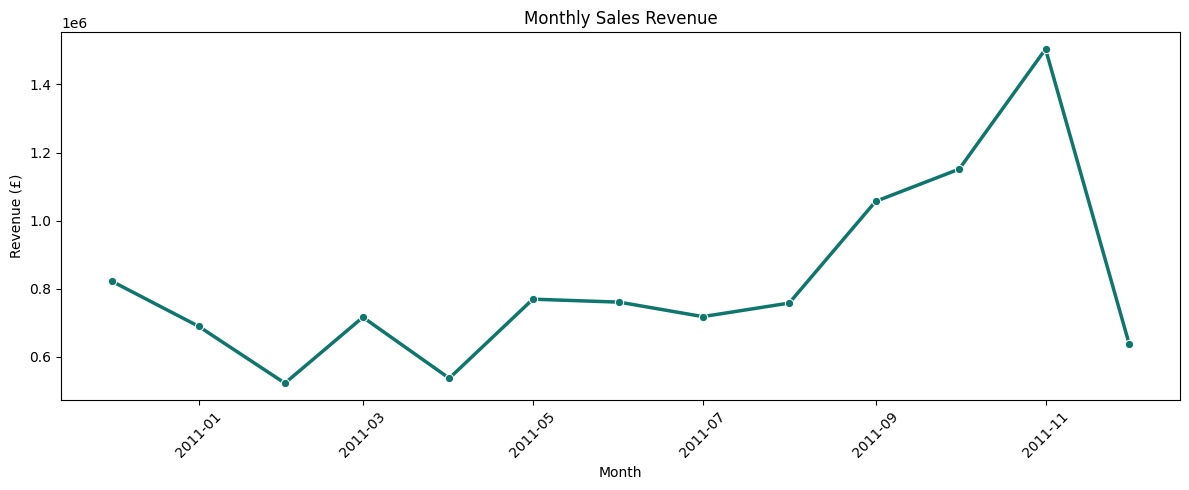

In [77]:

# Plot monthly revenue
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Revenue",
    marker="o",
    color="#0F766E",
    linewidth=2.5,
    markersize=6
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- Monthly revenue fluctuates throughout the observation period, with a noticeable increase from September 2011 and a peak of approximately £1.5 million in November.
- Revenue drops in December, but the dataset only covers transactions through 9 December 2011. Therefore, December is an incomplete month and should not be directly compared with full months.


### 5.3 Top-Performing Products

- Product-level analysis helps identify the items that contribute most to sales revenue.

- We will rank products by total revenue and compare their revenue, units sold, and number of orders.


### Checking Unusually Large Quantities

- Before finalizing the product ranking, we inspect unusually large quantities. A single transaction with an extreme quantity can significantly affect total revenue and the ranking of products.
- These records will be reviewed before deciding whether any adjustment is necessary.

In [83]:
# Find transactions with unusually large quantities
large_quantity_rows = sales_df.loc[
    sales_df["Quantity"] >= 10_000,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "Revenue",
        "InvoiceDate",
        "Country"
    ]
].sort_values("Quantity", ascending=False)

# Display the transactions for inspection
display(large_quantity_rows)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,InvoiceDate,Country
523404,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,2011-12-09 09:15:00,United Kingdom
59649,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,2011-01-18 10:01:00,United Kingdom


- Two transactions contain unusually large quantities: 80,995 units of PAPER CRAFT, LITTLE BIRDIE and 74,215 units of MEDIUM CERAMIC TOP STORAGE JAR.
- These transactions can have a significant effect on total product revenue and ranking. However, a large quantity alone does not prove that a transaction is incorrect, so both records are retained for the current analysis.

In [79]:
# Exclude non-product entries from product ranking
non_product_codes = {"DOT", "POST", "M", "D"}

non_product_descriptions = (
    r"POSTAGE|MANUAL|DISCOUNT|BANK CHARGES|AMAZON FEE"
)

product_df = sales_df.loc[
    ~sales_df["StockCode"].str.upper().isin(non_product_codes)
    & ~sales_df["Description"].str.contains(
        non_product_descriptions,
        case=False,
        na=False,
        regex=True
    )
].copy()

# Aggregate sales metrics by product
product_sales = (
    product_df.groupby("StockCode")
    .agg(
        Product_Name=("Description", "first"),
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
)

# Select the ten products with the highest revenue
top_products = (
    product_sales
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_products)

,StockCode,Product_Name,Revenue,Units_Sold,Orders
1310,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2465,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3407,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641,2198
2670,47566,PARTY BUNTING,99445.23,18283,1685
3387,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
1942,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
1006,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160
3194,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
2845,79321,CHILLI LIGHTS,54096.36,10302,661


- REGENCY CAKESTAND 3 TIER ranks first with approximately £174,157 in revenue, followed by PAPER CRAFT, LITTLE BIRDIE with approximately £168,470.
- However, the second product's revenue comes from a single transaction containing 80,995 units. This means its high ranking reflects an unusually large order rather than frequent purchases across many orders.
- MEDIUM CERAMIC TOP STORAGE JAR also has a high total quantity, partly influenced by a single unusually large transaction. For this reason, revenue, units sold, and order counts should be considered together when interpreting product performance.

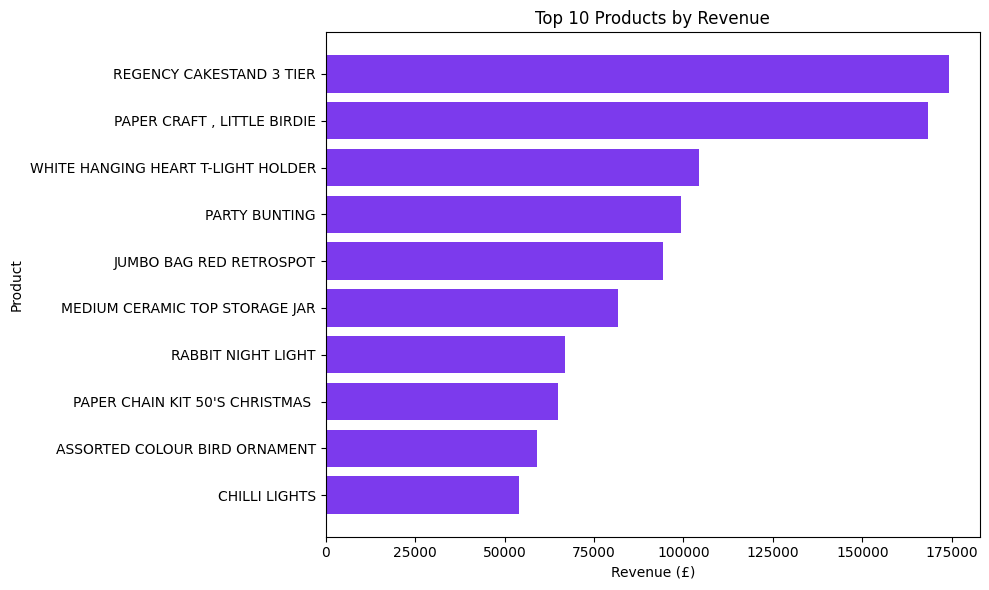

In [82]:
# Plot the top ten products by revenue
plot_products = top_products.sort_values(
    "Revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_products["Product_Name"],
    plot_products["Revenue"],
    color="#7C3AED"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

- The chart compares the ten highest-revenue products after excluding postage, manual entries, discounts, and other non-product records.
- REGENCY CAKESTAND 3 TIER has the highest revenue, while PAPER CRAFT, LITTLE BIRDIE ranks second. The unusually large transaction identified earlier has a strong influence on the second product's position.
- The results show why revenue alone may not fully represent product popularity. Order frequency and unusually large transactions should also be considered when evaluating product performance.


### 5.4 Sales by Country

- Country-level analysis helps identify the markets contributing most to revenue.
- We will compare revenue, order volume, and units sold across countries.


In [64]:

# Aggregate sales metrics by country
country_sales = (
    sales_df.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

# Rank countries by revenue
country_sales = country_sales.sort_values(
    "Revenue",
    ascending=False
)

# Display the top ten countries
display(country_sales.head(10))


,Country,Revenue,Orders,Units_Sold
36,United Kingdom,9001744.094,18020,4646906
24,Netherlands,285446.340,94,200361
10,EIRE,283140.520,288,147007
14,Germany,228678.400,458,119154
13,France,209625.370,392,112060
0,Australia,138453.810,57,83891
31,Spain,61558.560,90,27933
33,Switzerland,57067.600,54,30617
3,Belgium,41196.340,98,23237
32,Sweden,38367.830,36,36078


- The United Kingdom is the largest market, generating approximately £9.00 million in revenue from 18,020 orders.
- The Netherlands and EIRE are the next largest markets by revenue, but their sales are much lower than those of the United Kingdom. This indicates that the business relies heavily on its UK market.

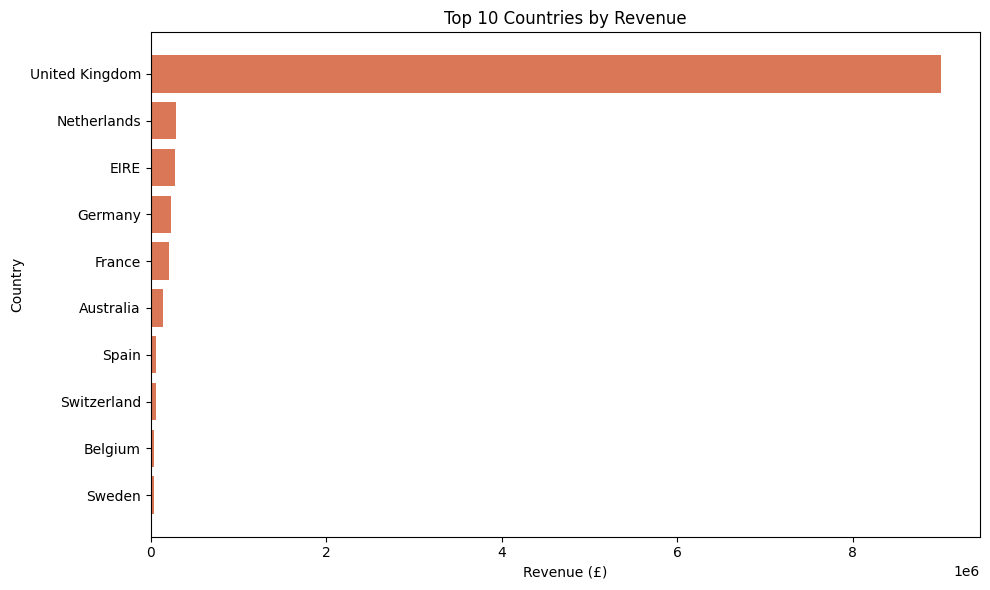

In [81]:

# Prepare the top ten countries for plotting
top_countries = (
    country_sales.head(10)
    .sort_values("Revenue")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Revenue"],
    color="#D97757"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


- The chart highlights the difference between the United Kingdom and the other leading markets. UK revenue is substantially higher, making the remaining countries appear much smaller in comparison.
- This concentration suggests that the UK is the main market in this dataset. Further analysis could explore the performance and growth opportunities of individual international markets.

---

## 6. Customer Segmentation (RFM Analysis)

RFM analysis helps us understand customer purchasing behavior using three metrics:

- **Recency:** How recently did the customer purchase?
- **Frequency:** How many distinct orders did the customer place?
- **Monetary:** How much revenue did the customer generate?

These metrics help identify valuable customers and opportunities for customer retention.


In [66]:

# Load the cleaned sales dataset
sales_df = pd.read_csv(
    "../data/processed/sales_clean.csv",
    parse_dates=["InvoiceDate"]
)

# Keep transactions with a known customer ID
customer_df = sales_df.loc[
    sales_df["CustomerID"].notna()
].copy()

# Convert customer IDs to integers
customer_df["CustomerID"] = (
    customer_df["CustomerID"].astype("int64")
)

print(f"Sales transactions: {len(sales_df):,}")
print(f"Identifiable customer transactions: {len(customer_df):,}")
print(f"Unique customers: {customer_df['CustomerID'].nunique():,}")


C:\Users\MYIII_M_A_505\AppData\Local\Temp\ipykernel_5136\4130333543.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df = pd.read_csv(


Sales transactions: 524,878
Identifiable customer transactions: 392,692
Unique customers: 4,338


### 6.1 Calculating RFM Metrics

- We aggregate transactions at the customer level.
- The reference date is set to one day after the last recorded transaction. 
- This allows us to calculate recency consistently using the historical dataset.


In [67]:

# Set the reference date to one day after the last transaction
snapshot_date = (
    sales_df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

# Calculate the last purchase date, order count, and total revenue
rfm = (
    customer_df
    .groupby("CustomerID")
    .agg(
        LastPurchaseDate=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# Calculate the number of days since the last purchase
rfm["Recency"] = (
    snapshot_date - rfm["LastPurchaseDate"].dt.normalize()
).dt.days

# Arrange columns for easier reading
rfm = rfm[
    [
        "CustomerID",
        "LastPurchaseDate",
        "Recency",
        "Frequency",
        "Monetary"
    ]
]

display(rfm.head(10))


,CustomerID,LastPurchaseDate,Recency,Frequency,Monetary
0,12346,2011-01-18 10:01:00,326,1,77183.60
1,12347,2011-12-07 15:52:00,3,7,4310.00
2,12348,2011-09-25 13:13:00,76,4,1797.24
3,12349,2011-11-21 09:51:00,19,1,1757.55
4,12350,2011-02-02 16:01:00,311,1,334.40
5,12352,2011-11-03 14:37:00,37,8,2506.04
6,12353,2011-05-19 17:47:00,205,1,89.00
7,12354,2011-04-21 13:11:00,233,1,1079.40
8,12355,2011-05-09 13:49:00,215,1,459.40
9,12356,2011-11-17 08:40:00,23,3,2811.43



### 6.2 RFM Scoring

- Each customer receives a score from 1 to 5 for each RFM metric.
- Higher Recency scores represent more recent purchases.
- Higher Frequency and Monetary scores represent more frequent purchases and greater revenue.
- Scores are based on each customer's relative position within the dataset.


In [68]:

# Rank customers by recency, frequency, and monetary value
recency_rank = rfm["Recency"].rank(
    method="average",
    pct=True
)

frequency_rank = rfm["Frequency"].rank(
    method="average",
    pct=True
)

monetary_rank = rfm["Monetary"].rank(
    method="average",
    pct=True
)

# Assign Recency scores: lower recency means a higher score
rfm["R_Score"] = (
    6 - np.ceil(recency_rank * 5)
).clip(1, 5).astype(int)

# Assign Frequency scores: more orders mean a higher score
rfm["F_Score"] = (
    np.ceil(frequency_rank * 5)
).clip(1, 5).astype(int)

# Assign Monetary scores: greater revenue means a higher score
rfm["M_Score"] = (
    np.ceil(monetary_rank * 5)
).clip(1, 5).astype(int)

# Combine the three scores into a single RFM code
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(
    rfm[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(10)
)


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,3,7,4310.00,5,5,5,555
2,12348,76,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,311,1,334.40,1,1,2,112
5,12352,37,8,2506.04,3,5,5,355
6,12353,205,1,89.00,1,1,1,111
7,12354,233,1,1079.40,1,1,4,114
8,12355,215,1,459.40,1,1,2,112
9,12356,23,3,2811.43,4,3,5,435


### 6.3 Customer Segmentation

- We use the RFM scores to assign customers to interpretable segments.

- These segments help distinguish high-value customers, loyal customers, recent buyers, and customers who may need re-engagement.


In [69]:

# Define rules for each customer segment
conditions = [
    # High scores across all three metrics
    (
        (rfm["R_Score"] >= 4)
        & (rfm["F_Score"] >= 4)
        & (rfm["M_Score"] >= 4)
    ),

    # Previously active customers who may be at risk
    (
        (rfm["R_Score"] <= 2)
        & (rfm["F_Score"] >= 3)
    ),

    # Customers with low recency and low purchase frequency
    (
        (rfm["R_Score"] <= 2)
        & (rfm["F_Score"] <= 2)
    ),

    # Recent customers with strong frequency and monetary scores
    (
        (rfm["R_Score"] >= 3)
        & (rfm["F_Score"] >= 4)
        & (rfm["M_Score"] >= 3)
    ),

    # Recent customers with some repeat purchases
    (
        (rfm["R_Score"] >= 4)
        & (rfm["F_Score"].between(2, 3))
    ),

    # Customers with a recent purchase but low frequency
    (
        (rfm["R_Score"] >= 4)
        & (rfm["F_Score"] == 1)
    ),

    # Customers who may need additional attention
    (
        (rfm["R_Score"] == 3)
        & (rfm["F_Score"] <= 2)
    )
]

# Names corresponding to the conditions above
segment_names = [
    "Champions",
    "At Risk",
    "Hibernating",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Customers",
    "Needs Attention"
]

# Assign the first matching segment to each customer
rfm["Segment"] = np.select(
    conditions,
    segment_names,
    default="Other"
)

display(
    rfm[
        ["CustomerID", "RFM_Score", "Segment"]
    ].head(10)
)


,CustomerID,RFM_Score,Segment
0,12346,115,Hibernating
1,12347,555,Champions
2,12348,244,At Risk
3,12349,414,Recent Customers
4,12350,112,Hibernating
5,12352,355,Loyal Customers
6,12353,111,Hibernating
7,12354,114,Hibernating
8,12355,112,Hibernating
9,12356,435,Potential Loyalists


### 6.4 Segment Performance

- We compare customer segments by customer count, total revenue, and average RFM metrics.
- This helps us identify which groups contribute most to revenue and which groups may benefit from retention campaigns.


In [70]:

# Summarize customer and revenue metrics by segment
segment_summary = (
    rfm
    .groupby("Segment")
    .agg(
        Customers=("CustomerID", "nunique"),
        Total_Revenue=("Monetary", "sum"),
        Avg_Recency_Days=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .reset_index()
)

# Calculate each segment's share of total customer revenue
total_customer_revenue = rfm["Monetary"].sum()

segment_summary["Revenue_Share_Pct"] = (
    segment_summary["Total_Revenue"]
    / total_customer_revenue
    * 100
)

# Rank segments by revenue
segment_summary = segment_summary.sort_values(
    "Total_Revenue",
    ascending=False
)

display(segment_summary.round(2))


,Segment,Customers,Total_Revenue,Avg_Recency_Days,Avg_Frequency,Avg_Monetary,Revenue_Share_Pct
1,Champions,912,5678277.39,12.84,11.49,6226.18,63.89
0,At Risk,765,919286.91,154.57,3.21,1201.68,10.34
3,Loyal Customers,364,817853.92,40.21,5.86,2246.85,9.20
6,Potential Loyalists,483,580986.22,16.95,2.42,1202.87,6.54
2,Hibernating,962,419725.82,222.85,1.00,436.31,4.72
5,Other,321,276814.89,50.40,2.51,862.35,3.11
4,Needs Attention,295,118063.09,53.46,1.00,400.21,1.33
7,Recent Customers,236,76200.65,19.42,1.00,322.88,0.86



### 6.5 Visualizing Customer Segments

- Visualizations make it easier to compare segment sizes and revenue contribution.
- We first compare the number of customers in each segment.


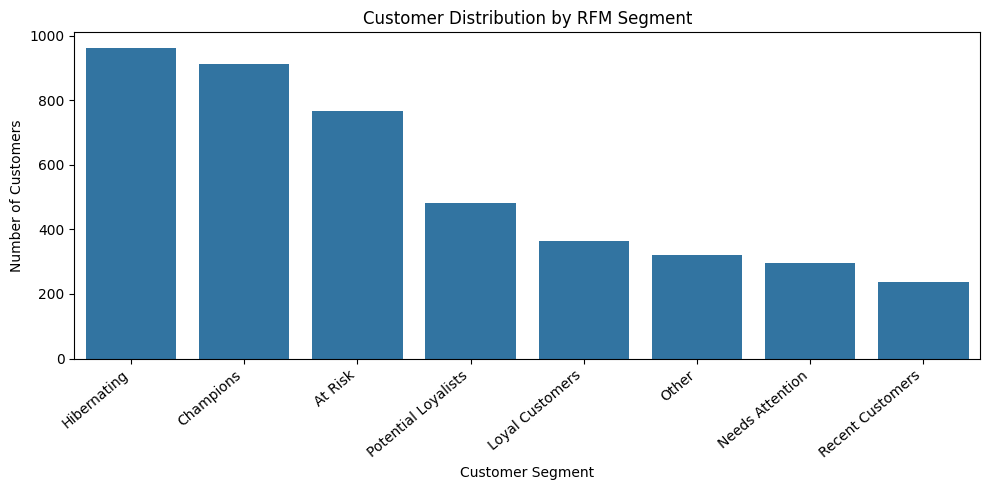

In [71]:

# Count customers in each segment
segment_counts = (
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
    .sort_values("Customers", ascending=False)
)

# Plot the number of customers by segment
plt.figure(figsize=(10, 5))

sns.barplot(
    data=segment_counts,
    x="Segment",
    y="Customers"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


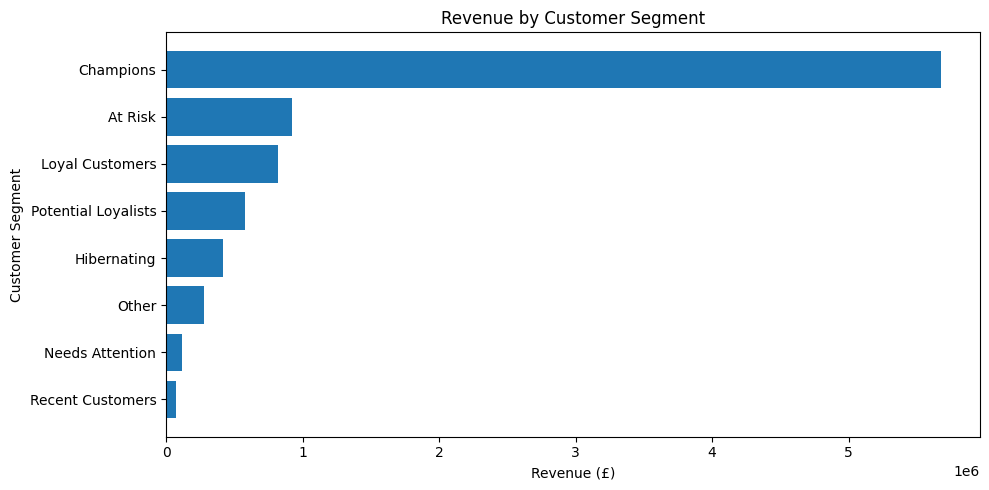

In [72]:

# Sort segments by revenue for a clearer horizontal chart
revenue_plot = segment_summary.sort_values(
    "Total_Revenue",
    ascending=True
)

# Plot revenue generated by each segment
plt.figure(figsize=(10, 5))

plt.barh(
    revenue_plot["Segment"],
    revenue_plot["Total_Revenue"]
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()



### 6.6 Saving the RFM Results

We save the customer-level RFM metrics and segment summary as separate CSV files.

These outputs can be reused in SQL analysis and Power BI without repeating the entire segmentation process.


In [73]:

# Create the processed data folder if needed
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save customer-level RFM scores and segments
rfm.to_csv(
    processed_dir / "customer_rfm.csv",
    index=False
)

# Save the segment-level summary
segment_summary.to_csv(
    processed_dir / "rfm_segment_summary.csv",
    index=False
)

print("RFM results saved successfully.")
print(f"Customers analyzed: {len(rfm):,}")
print(f"Customer segments: {rfm['Segment'].nunique()}")


RFM results saved successfully.
Customers analyzed: 4,338
Customer segments: 8
